<a href="https://colab.research.google.com/github/mmarzafaridob24ti-sys/Project_ProbStat/blob/main/Projek_Probabilitas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()
print("data berhasil diupload")

Saving 3TIC_10_HargaTBSPenetapan_TimProvinsi.xlsx to 3TIC_10_HargaTBSPenetapan_TimProvinsi.xlsx
data berhasil diupload


In [ ]:
# Membaca file data
file_path = '3TIC_10_HargaTBSPenetapan_TimProvinsi.xlsx'
df = pd.read_excel(file_path)

print(f"Jumlah Baris & Kolom: {df.shape}")
df.head()

Jumlah Baris & Kolom: (870, 9)


,Periode,USD/IDR,Kelapa Sawit Umur,Indeks K (%),Rendemen CPO (%),Harga CPO (Rp/Kg),Rendemen Kernel (%),Harga Kernel (Rp/Kg),Harga TBS (Rp/Kg)
0,Minggu 1,"16.203,20",3,89.88,17.07,14738.3,3.99,10788.61,2651.06
1,Minggu 1,"16.203,20",4,89.88,18.34,14738.3,4.42,10788.61,2863.56
2,Minggu 1,"16.203,20",5,89.88,19.17,14738.3,4.61,10788.61,2991.43
3,Minggu 1,"16.203,20",6,89.88,19.79,14738.3,4.74,10788.61,3085.79
4,Minggu 1,"16.203,20",7,89.88,20.22,14738.3,4.84,10788.61,3152.46


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 870 entries, 0 to 869
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Periode               870 non-null    object 
 1   USD/IDR               870 non-null    object 
 2   Kelapa Sawit Umur     870 non-null    object 
 3   Indeks K (%)          870 non-null    float64
 4   Rendemen CPO (%)      870 non-null    float64
 5   Harga CPO (Rp/Kg)     870 non-null    float64
 6   Rendemen Kernel (%)   870 non-null    float64
 7   Harga Kernel (Rp/Kg)  870 non-null    float64
 8   Harga TBS (Rp/Kg)     870 non-null    float64
dtypes: float64(6), object(3)
memory usage: 61.3+ KB


In [ ]:
def statistik_deskriptif_lengkap(df):
    # Ambil hanya kolom numerik untuk perhitungan statistik tertentu
    df_numeric = df.select_dtypes(include=[np.number])

    # 1. Ambil statistik dasar bawaan dari df.describe()
    desc = df_numeric.describe()

    # 2. Hitung metrik tambahan dengan kolom numerik saja
    median = df_numeric.median().to_frame(name='median').T
    mode = df_numeric.mode().iloc[0].to_frame(name='mode').T
    varians = df_numeric.var().to_frame(name='variance').T
    range_data = (df_numeric.max() - df_numeric.min()).to_frame(name='range').T
    iqr = (df_numeric.quantile(0.75) - df_numeric.quantile(0.25)).to_frame(name='iqr').T
    kemiringan = df_numeric.skew().to_frame(name='skewness').T
    keruncingan = df_numeric.kurt().to_frame(name='kurtosis').T

    statistik_lengkap = pd.concat([desc, median, mode, varians, range_data, iqr, kemiringan, keruncingan])

    return statistik_lengkap

tabel_statistik = statistik_deskriptif_lengkap(df)
display(tabel_statistik)

,Indeks K (%),Rendemen CPO (%),Harga CPO (Rp/Kg),Rendemen Kernel (%),Harga Kernel (Rp/Kg),Harga TBS (Rp/Kg)
count,870.000000,870.000000,870.000000,870.000000,8.700000e+02,870.000000
mean,90.061782,19.446552,14053.208747,4.790506,1.187898e+04,2978.599563
std,1.914324,1.757230,525.031792,0.443579,1.128590e+03,304.077671
min,85.780000,9.990000,12766.610000,2.610000,9.572060e+03,1576.360000
25%,88.720000,18.692500,13642.730000,4.580000,1.085254e+04,2775.217500
50%,90.400000,19.360000,14126.100000,4.890000,1.164963e+04,2993.930000
75%,91.630000,21.007500,14470.680000,5.140000,1.288681e+04,3195.767500
max,94.530000,22.020000,15032.760000,5.640000,1.377081e+04,3719.420000
median,90.400000,19.360000,14126.100000,4.890000,1.164963e+04,2993.930000
mode,91.260000,18.890000,14581.250000,4.890000,1.363357e+04,2993.440000


In [ ]:
# 3.1 Bersihkan kolom USD/IDR dari titik dan koma jika berupa string
if df['USD/IDR'].dtype == 'object':
    df['USD/IDR'] = df['USD/IDR'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False)
    df['USD/IDR'] = pd.to_numeric(df['USD/IDR'], errors='coerce')

# 3.2 Cek Missing Value dan Duplikat
print("=== Jumlah Missing Value ===")
print(df.isnull().sum())

print(f"\nJumlah Data Duplikat: {df.duplicated().sum()}")


=== Jumlah Missing Value ===
Periode                 0
USD/IDR                 0
Kelapa Sawit Umur       0
Indeks K (%)            0
Rendemen CPO (%)        0
Harga CPO (Rp/Kg)       0
Rendemen Kernel (%)     0
Harga Kernel (Rp/Kg)    0
Harga TBS (Rp/Kg)       0
dtype: int64

Jumlah Data Duplikat: 0


In [ ]:
# Konversi seluruh kolom numerik
num_cols = ['USD/IDR', 'Indeks K (%)', 'Rendemen CPO (%)',
            'Harga CPO (Rp/Kg)', 'Rendemen Kernel (%)',
            'Harga Kernel (Rp/Kg)', 'Harga TBS (Rp/Kg)']

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')


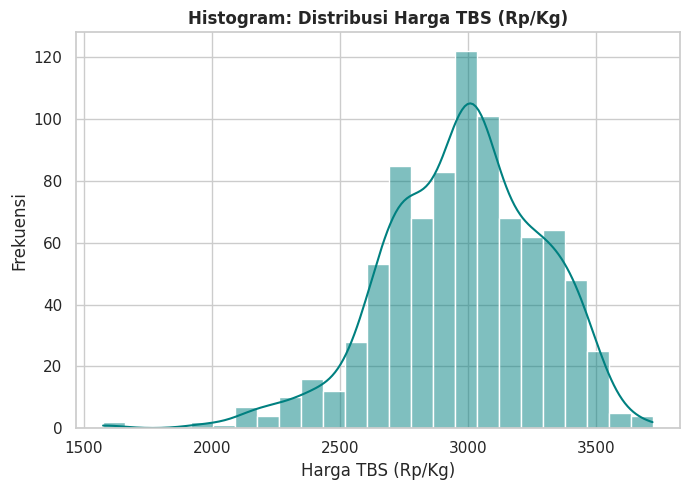

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

# Load Data
file_path = '3TIC_10_HargaTBSPenetapan_TimProvinsi.xlsx'
df = pd.read_excel(file_path)

# Cleaning & Konversi Data Numerik
if df['USD/IDR'].dtype == 'object':
    df['USD/IDR'] = df['USD/IDR'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False)

num_cols = ['USD/IDR', 'Indeks K (%)', 'Rendemen CPO (%)', 'Harga CPO (Rp/Kg)', 'Rendemen Kernel (%)', 'Harga Kernel (Rp/Kg)', 'Harga TBS (Rp/Kg)']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Plot Histogram
plt.figure(figsize=(7, 5))
sns.histplot(df['Harga TBS (Rp/Kg)'], kde=True, color='teal')
plt.title('Histogram: Distribusi Harga TBS (Rp/Kg)', fontsize=12, fontweight='bold')
plt.xlabel('Harga TBS (Rp/Kg)')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

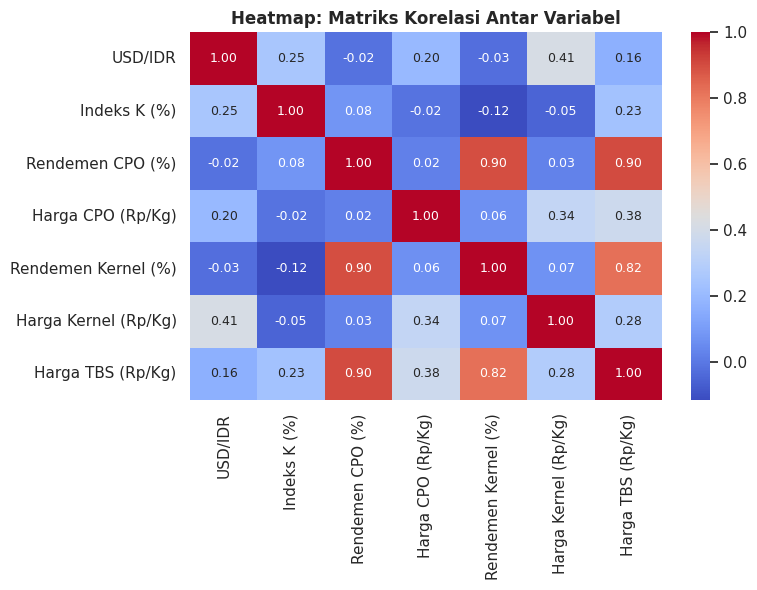

In [ ]:
corr = df[num_cols].corr()

# Plot Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, annot_kws={"size": 9})
plt.title('Heatmap: Matriks Korelasi Antar Variabel', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

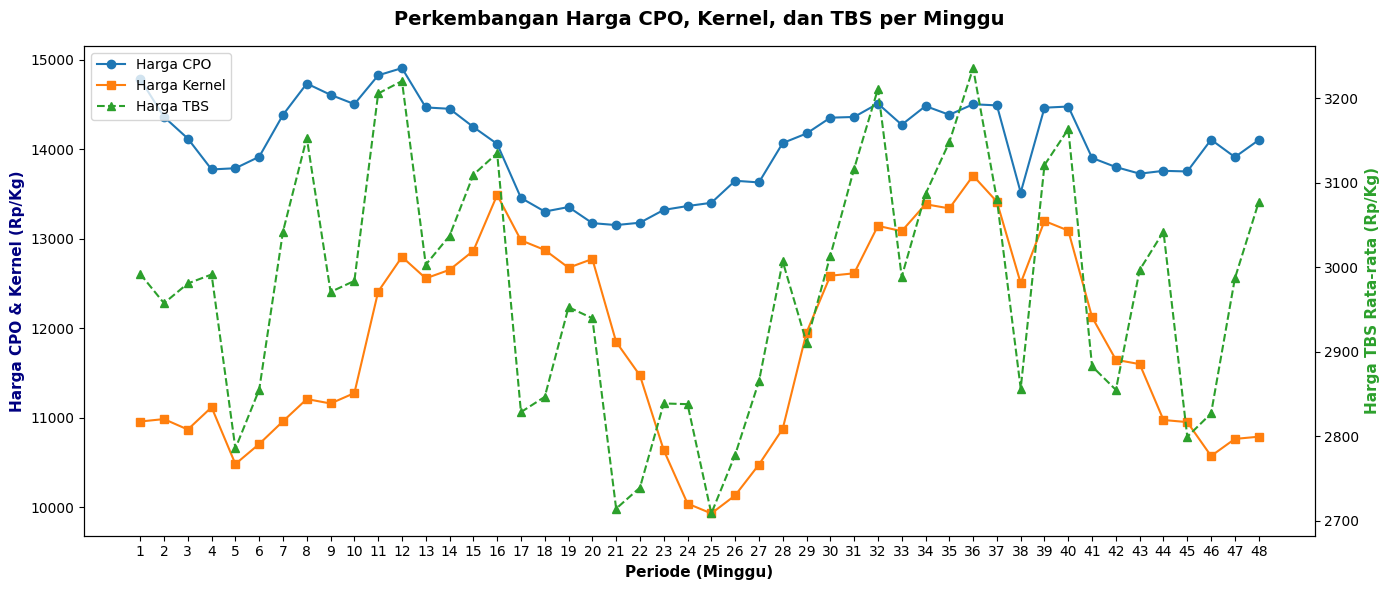

In [ ]:
df['Minggu_Num'] = df['Periode'].str.extract(r'(\d+)').astype(int)
df_sorted = df.sort_values('Minggu_Num')

# 3. Visualisasi Tren Harga
df_weekly = df_sorted.groupby(['Minggu_Num', 'Periode'])[['Harga CPO (Rp/Kg)', 'Harga Kernel (Rp/Kg)', 'Harga TBS (Rp/Kg)']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

color_cpo = 'tab:blue'
color_kernel = 'tab:orange'
ax1.set_xlabel('Periode (Minggu)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Harga CPO & Kernel (Rp/Kg)', color='navy', fontsize=11, fontweight='bold')
line1 = ax1.plot(df_weekly['Minggu_Num'], df_weekly['Harga CPO (Rp/Kg)'], color=color_cpo, marker='o', label='Harga CPO')
line2 = ax1.plot(df_weekly['Minggu_Num'], df_weekly['Harga Kernel (Rp/Kg)'], color=color_kernel, marker='s', label='Harga Kernel')

ax2 = ax1.twinx()
color_tbs = 'tab:green'
ax2.set_ylabel('Harga TBS Rata-rata (Rp/Kg)', color=color_tbs, fontsize=11, fontweight='bold')
line3 = ax2.plot(df_weekly['Minggu_Num'], df_weekly['Harga TBS (Rp/Kg)'], color=color_tbs, marker='^', linestyle='--', label='Harga TBS')

lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Perkembangan Harga CPO, Kernel, dan TBS per Minggu', fontsize=14, fontweight='bold', pad=15)
plt.xticks(df_weekly['Minggu_Num'])
plt.tight_layout()
plt.show()

/tmp/ipykernel_3281/1148421477.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_filtered, x='Umur_Clean', y='Harga TBS (Rp/Kg)', palette='Set2')


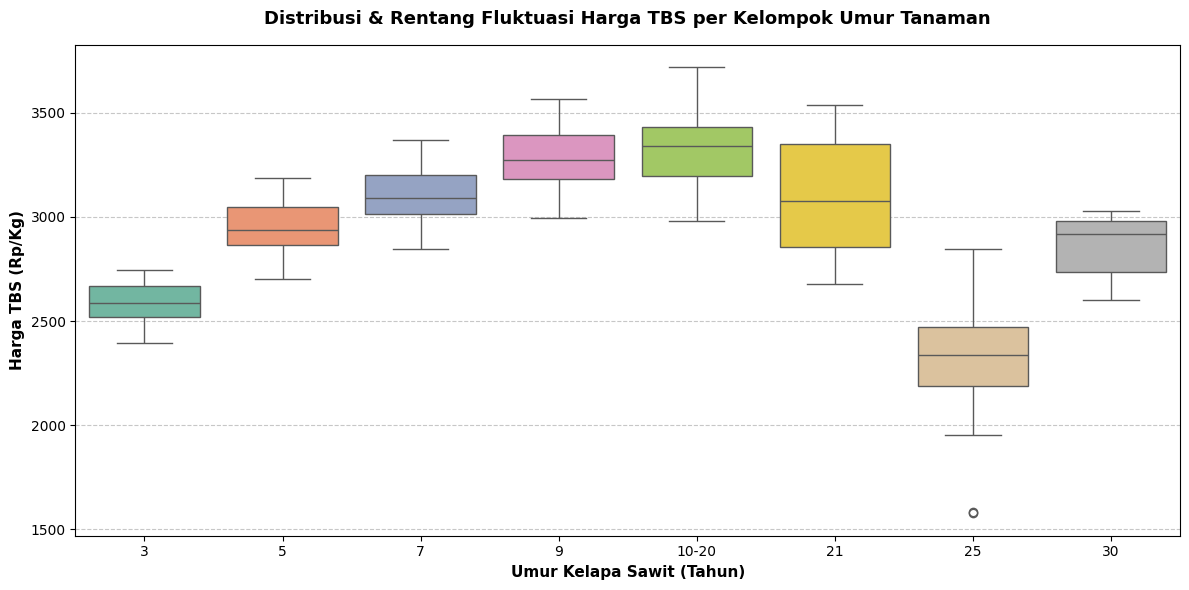

In [ ]:
df['Umur_Clean'] = df['Kelapa Sawit Umur'].astype(str).replace({'2026-10-20 00:00:00': '10-20'})

# 3. Filter berdasarkan kelompok umur pilihan
umur_pilihan = ['3', '5', '7', '9', '10-20', '21', '25', '30']
df_filtered = df[df['Umur_Clean'].isin(umur_pilihan)]

# 4. Plot Boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_filtered, x='Umur_Clean', y='Harga TBS (Rp/Kg)', palette='Set2')

plt.title('Distribusi & Rentang Fluktuasi Harga TBS per Kelompok Umur Tanaman', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Umur Kelapa Sawit (Tahun)', fontsize=11, fontweight='bold')
plt.ylabel('Harga TBS (Rp/Kg)', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

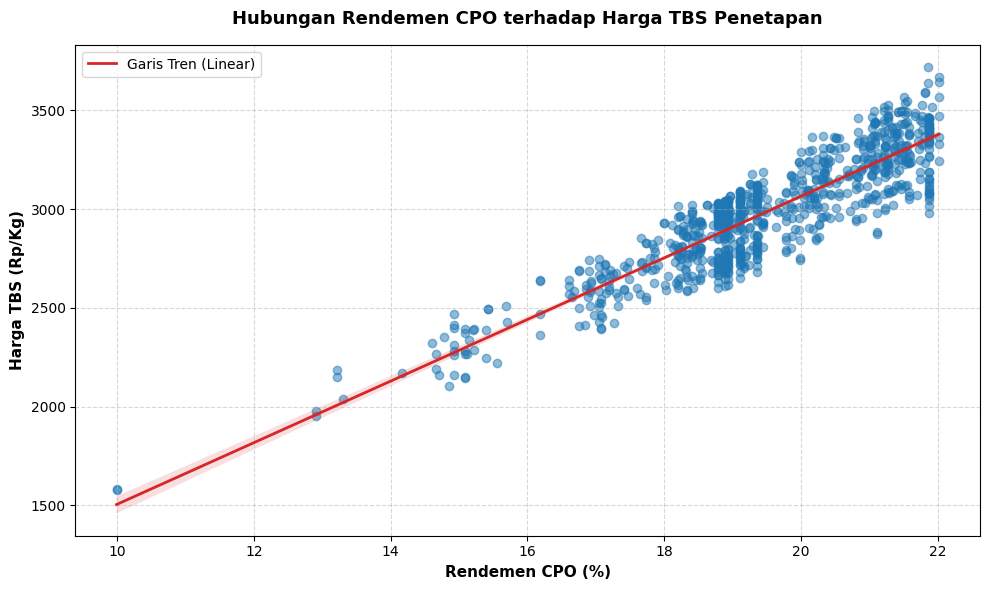

In [ ]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df,
    x='Rendemen CPO (%)',
    y='Harga TBS (Rp/Kg)',
    scatter_kws={'alpha': 0.5, 'color': '#1f77b4'},
    line_kws={'color': '#d62728', 'linewidth': 2, 'label': 'Garis Tren (Linear)'}
)

plt.title('Hubungan Rendemen CPO terhadap Harga TBS Penetapan', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Rendemen CPO (%)', fontsize=11, fontweight='bold')
plt.ylabel('Harga TBS (Rp/Kg)', fontsize=11, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

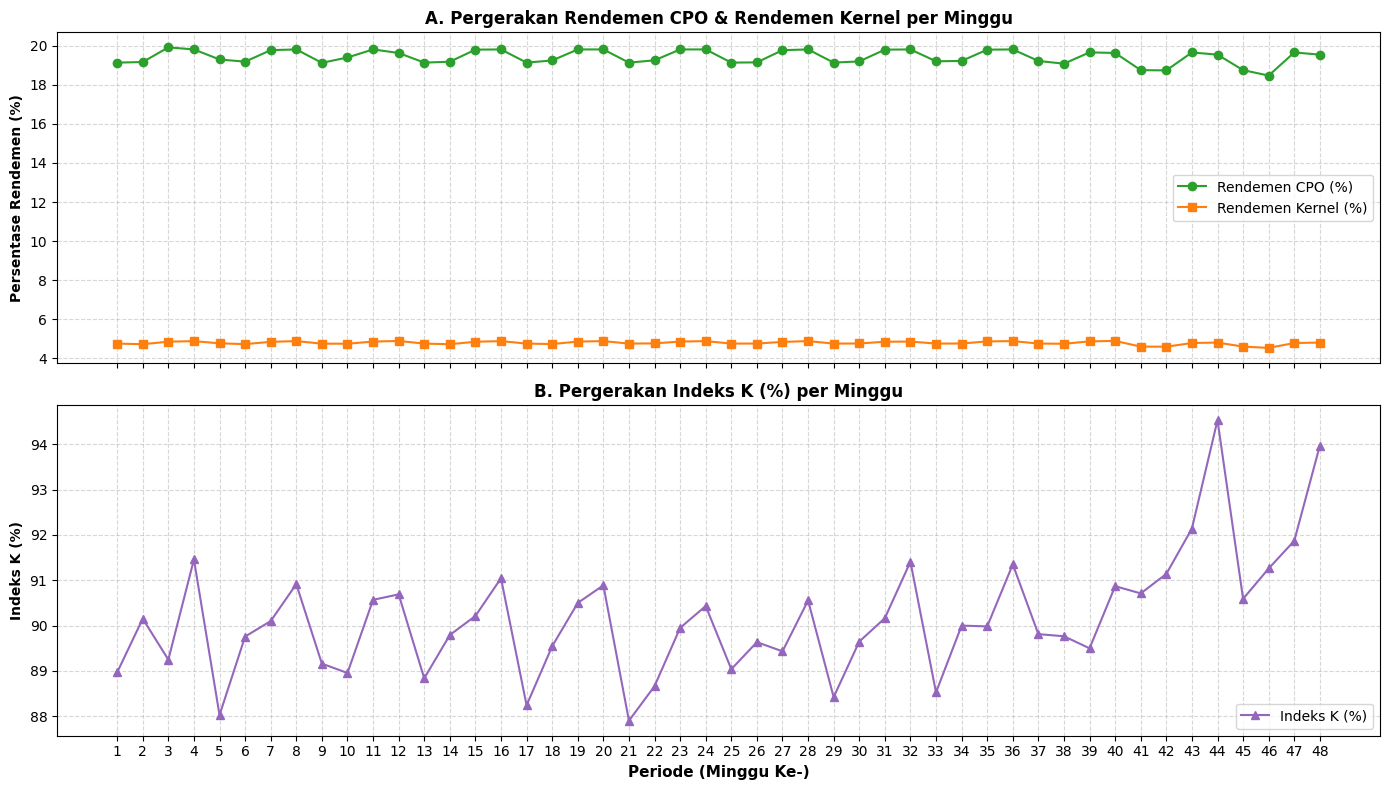

In [ ]:
df['Minggu_Num'] = df['Periode'].str.extract(r'(\d+)').astype(int)

# Rata-rata indikator per minggu
df_weekly = df.sort_values('Minggu_Num').groupby(['Minggu_Num', 'Periode'])[['Rendemen CPO (%)', 'Rendemen Kernel (%)', 'Indeks K (%)']].mean().reset_index()

# 2. Buat Subplots 2 Panel
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Panel 1: Rendemen CPO vs Kernel
axes[0].plot(df_weekly['Minggu_Num'], df_weekly['Rendemen CPO (%)'], color='#2ca02c', marker='o', label='Rendemen CPO (%)')
axes[0].plot(df_weekly['Minggu_Num'], df_weekly['Rendemen Kernel (%)'], color='#ff7f0e', marker='s', label='Rendemen Kernel (%)')
axes[0].set_ylabel('Persentase Rendemen (%)', fontsize=10, fontweight='bold')
axes[0].set_title('A. Pergerakan Rendemen CPO & Rendemen Kernel per Minggu', fontsize=12, fontweight='bold')
axes[0].legend(loc='center right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Indeks K
axes[1].plot(df_weekly['Minggu_Num'], df_weekly['Indeks K (%)'], color='#9467bd', marker='^', label='Indeks K (%)')
axes[1].set_ylabel('Indeks K (%)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Periode (Minggu Ke-)', fontsize=11, fontweight='bold')
axes[1].set_title('B. Pergerakan Indeks K (%) per Minggu', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.xticks(df_weekly['Minggu_Num'])
plt.tight_layout()
plt.show()

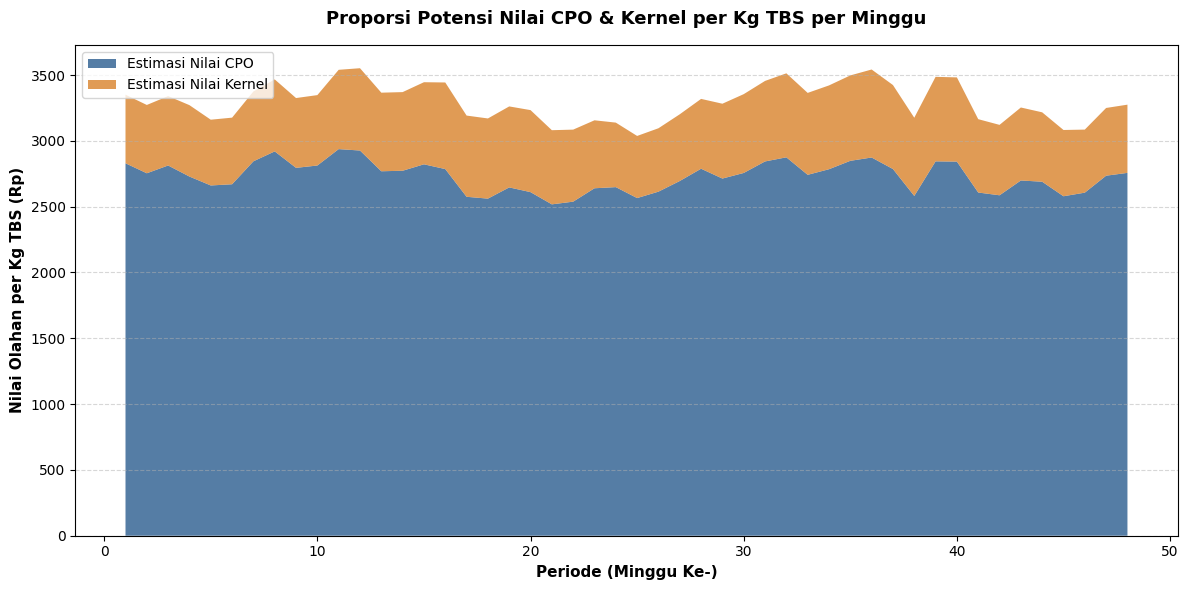

In [ ]:
df['Minggu_Num'] = df['Periode'].str.extract(r'(\d+)').astype(int)

# Hitung estimasi nilai kontribusi CPO & Kernel sebelum Indeks K
df['Nilai_CPO'] = (df['Rendemen CPO (%)'] / 100) * df['Harga CPO (Rp/Kg)']
df['Nilai_Kernel'] = (df['Rendemen Kernel (%)'] / 100) * df['Harga Kernel (Rp/Kg)']

df_weekly = df.sort_values('Minggu_Num').groupby('Minggu_Num')[['Nilai_CPO', 'Nilai_Kernel']].mean()

# 2. Plot Area Chart
plt.figure(figsize=(12, 6))
plt.stackplot(df_weekly.index, df_weekly['Nilai_CPO'], df_weekly['Nilai_Kernel'],
              labels=['Estimasi Nilai CPO', 'Estimasi Nilai Kernel'],
              colors=['#2b5c8f', '#d9822b'], alpha=0.8)

plt.title('Proporsi Potensi Nilai CPO & Kernel per Kg TBS per Minggu', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Periode (Minggu Ke-)', fontsize=11, fontweight='bold')
plt.ylabel('Nilai Olahan per Kg TBS (Rp)', fontsize=11, fontweight='bold')
plt.legend(loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

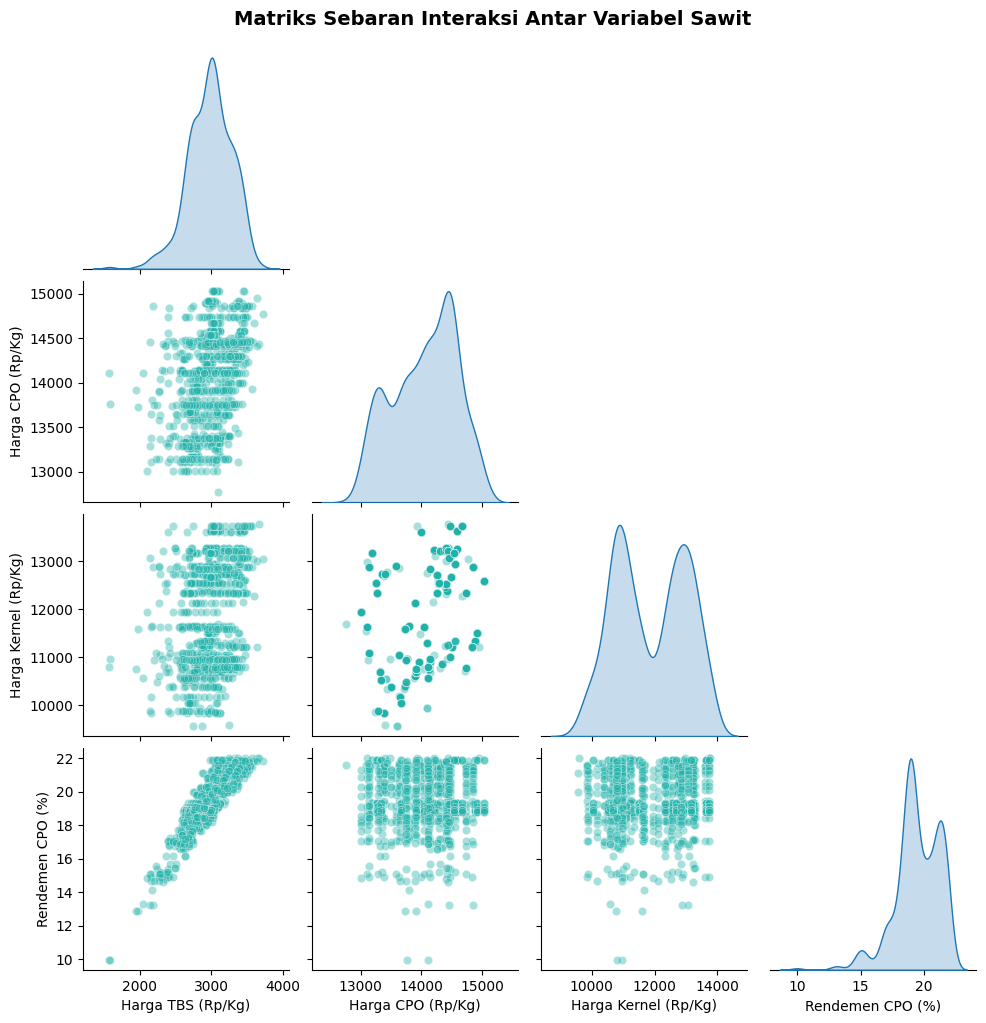

In [ ]:
cols = ['Harga TBS (Rp/Kg)', 'Harga CPO (Rp/Kg)', 'Harga Kernel (Rp/Kg)', 'Rendemen CPO (%)']

# 3. Plot Pairplot
g = sns.pairplot(df[cols], corner=True, diag_kind='kde', plot_kws={'alpha': 0.4, 'color': '#20b2aa'})
g.fig.suptitle('Matriks Sebaran Interaksi Antar Variabel Sawit', y=1.02, fontsize=14, fontweight='bold')

plt.show()